# Lab 02 – Maximum Likelihood Estimation (Extended)

This lab deepens your understanding of maximum likelihood estimation (MLE). Sections tagged with **(Extension)** go beyond the core material from Lessons 0–2 and can be treated as enrichment if you are short on time.


In [41]:
# TODO: import the libraries you will need (e.g., numpy, pandas, matplotlib, scipy.stats, scipy.optimize).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize



## 1. Introduction to Maximum Likelihood Estimation

Summarise in your own words the distinction between the probability of data given parameters and the likelihood of parameters given observed data. No code is required for this part.


## 2. Bernoulli Distribution: A Simple Case Study (Lessons 0–2)

### Question 1 — Derive and implement the Bernoulli MLE
- Simulate $N$ Bernoulli trials with success probability $p=0.6$ (e.g., the outcome of a simple A/B test).
- Derive the log-likelihood and the closed-form MLE for $p$.
- Implement a function `bernoulli_mle(data)` that returns the estimate $\hat p$ from the simulated sample.


In [53]:
# TODO: simulate Bernoulli data and implement bernoulli_mle(data).

p = 0.6
N = 1000

data = stats.bernoulli.rvs(p=p, size=N)

print(data)


def bernoulli_mle(data):

    closed_form = np.sum(data) / len(data)

    return closed_form # log_likelihood

bernoulli_mle(data)



[1 1 1 1 0 1 1 1 1 0 0 1 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 1 0 0 0 1 1 1 1 0 1
 1 1 1 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 1 0 1 1 1 1 1
 0 1 1 1 1 0 0 0 1 0 1 1 0 0 1 1 1 0 0 0 1 0 0 1 1 1 0 1 0 0 1 1 1 1 0 1 1
 0 0 0 1 1 1 0 1 0 0 0 1 0 1 0 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 0 1 1 0 0 0 1
 1 1 1 1 0 1 0 0 0 1 1 1 0 1 0 1 0 0 1 0 0 1 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1
 1 0 0 1 1 0 1 0 1 1 1 1 0 1 1 0 1 0 0 1 1 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1
 0 1 0 1 0 1 1 0 1 0 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 1 1 1 1 0 0 1 1 1 0 1
 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 1 0 0 1 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0
 1 1 1 1 1 1 0 1 0 1 0 1 1 1 0 1 1 1 0 1 0 0 0 1 1 1 0 1 1 1 0 0 0 1 0 0 1
 0 1 1 0 1 0 0 0 1 0 0 1 0 1 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 0 1 1 0 0 1 1
 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 1 0 1 1 1 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 1
 1 1 1 1 1 0 0 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 1 0 1 0 1 0 0 1 1 1 1 0 0 1 1
 1 0 0 1 0 1 1 0 1 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 1 1
 1 1 0 1 0 0 1 1 1 1 0 0 

np.float64(0.613)

### Question 2 — Visualise the Bernoulli log-likelihood
- Implement `bernoulli_log_likelihood(p, data)`.
- Evaluate the log-likelihood on a dense grid of $p \in (0,1)$ for your simulated sample.
- Plot the curve and mark the location of the MLE.


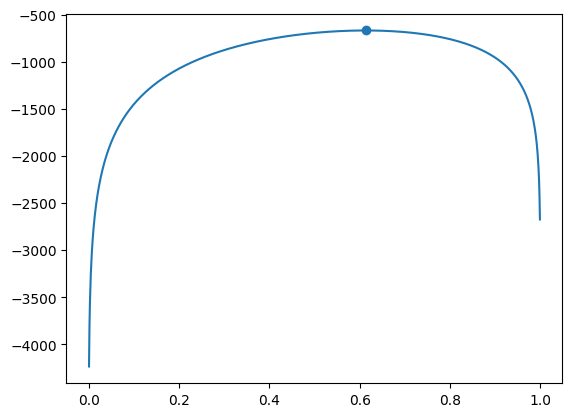

In [73]:
# TODO: implement the log-likelihood function and generate the plot.

list_trying = list(np.linspace(0.001 , 0.999, N))


def bernoulli_log_likelihood(p_term, data):
    log_likelihood = 0
    for sample in data: 
        term =  float(sample) * np.log(p_term) + float(1-sample) * np.log(1-p_term)
        log_likelihood += term

    return log_likelihood


def bernoulli_log_likelihood_sim(data): 
    max_log_likelihood = -999
    p_hat = 0

    likelihood_list = []

    for p_tried in list_trying:
        if ((1 - p_tried) == 0) or ((p_tried == 0)):
            continue 

        log_likelihood = bernoulli_log_likelihood(p_tried, data)
        likelihood_list.append(log_likelihood)
        if log_likelihood > max_log_likelihood:
            max_log_likelihood = log_likelihood
            p_hat = p_tried

    return p_hat, max_log_likelihood, likelihood_list

p_hat, max_log_likelihood, likelihood_list = bernoulli_log_likelihood_sim(data)


def plot_curve():
    plt.plot(list_trying, likelihood_list)
    plt.scatter(p_hat, max_log_likelihood)
plot_curve()



## 3. Real-World Application: Lifetime Data Analysis (Extension)

In this section you will work with the `lifetimes.txt` dataset containing material lifetime measurements (in thousands of hours).

### Question 3 — Explore the dataset
- Load the dataset into a `pandas` DataFrame.
- Report the sample size, mean, median, min/max, and standard deviation.
- Create a histogram and a boxplot to inspect the distribution.


count    20.000000
mean      0.885000
std       0.423364
min       0.100000
25%       0.600000
50%       0.800000
75%       1.300000
max       1.600000
Name: times, dtype: float64


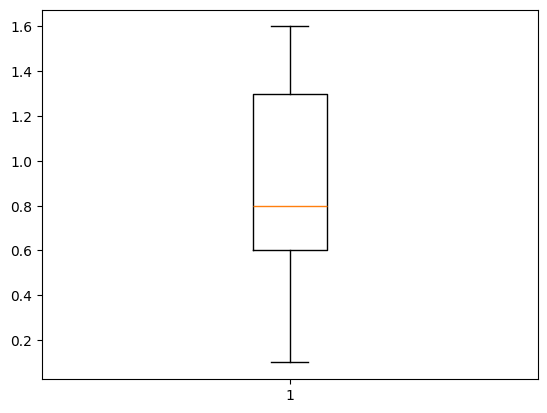

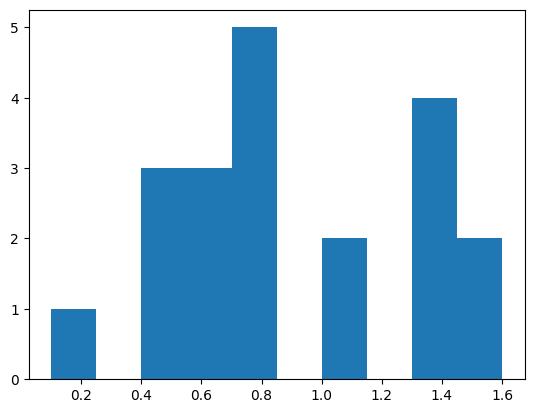

,times
0,1.6
1,1.3
2,1.1
3,0.8
4,1.1
5,0.8
6,0.4
7,0.1
8,1.3
9,0.6


In [81]:
# TODO: load the lifetime data and create the requested plots.

df = pd.read_csv('lifetimes.txt')

print(df['times'].describe())

def visualize_boxplot(df):
    plt.boxplot(df)
    plt.show()
    plt.hist(df)
    plt.show()


visualize_boxplot(df)
df


### Question 4 — Fit a Weibull model via MLE
- Implement helpers for the Weibull PDF and the negative log-likelihood of the shape parameter $a$ (assume the scale parameter is 1 for this exercise).
- Plot the negative log-likelihood over a reasonable grid of $a$ values.
- Use `scipy.optimize.minimize` with bounds to obtain the MLE $\hat a$.


In [ ]:
# TODO: implement the Weibull helpers, plot the negative log-likelihood and compute the MLE.

def weibull_pdf(k, ld, data):
    for x in data:
        if x >= 0:
            return k / ld * (x / ld) ** (k - 1) * np.exp(-(x/ld)**k)

alpha = np.linspace(0, 2.5, 10)
scale = 1 

def sim_model(alphs, scale, data):
    for alph in alphs:
        weibull_pdf(alph, scale, data)



weibull_pdf(alpha, scale, df['times'].values)
        
    

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

### Question 5 — Assess the fitted model
- Overlay the fitted Weibull density on top of the empirical histogram of the lifetimes.
- Comment on how well the model captures the data.


In [ ]:
# TODO: plot the histogram and overlay the fitted Weibull PDF.


## 4. Comparing MLE and Method of Moments (Extension)

### Question 6 — Implement a method-of-moments estimator and compare it to MLE
- Derive a method-of-moments estimate for the Weibull shape parameter.
- Implement a function `weibull_mom_estimator(data)`.
- Design a simulation study that compares the bias and MSE of the MLE and MoM estimators for several sample sizes (e.g., $n \in \{20, 50, 100, 200\}$).
- Present your results in tables or plots and discuss the findings.


In [ ]:
# TODO: implement the method-of-moments estimator and the simulation study.


## 5. Uncertainty Quantification (Extension)

### Question 7 — Approximate the standard error via observed Fisher information
- Compute (numerically) the observed Fisher information for the Weibull shape parameter at the MLE.
- Report the corresponding standard error and a Wald-style 95 % confidence interval.


In [ ]:
# TODO: compute the observed Fisher information, standard error, and confidence interval.


### Question 8 — Bootstrap confidence intervals
- Implement a bootstrap procedure (e.g., percentile interval) for the Weibull shape parameter.
- Compare the bootstrap interval with the Wald interval obtained above.


In [ ]:
# TODO: implement the bootstrap procedure and compare the intervals.


## 6. Summary and Reflection

### Question 9 — Summarise your findings
Provide a short written summary of the insights you gained from the lifetime analysis, highlighting the role of MLE, alternative estimators, and uncertainty quantification.
